# Ex1 - Filtering and Sorting Data



### Step 1. Import the necessary libraries

In [10]:
import pandas as pd
import numpy as np

### Step 2. Import the dataset from this [address](https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv). 

In [11]:
url = ("https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv")

### Step 3. Assign it to a variable called chipo.

In [22]:
chipo = pd.read_csv(url, sep="\t")      # es un .tsv: 
                                        # separado por tabuladores no por , por defecto
                                        # sep="\t"




In [13]:
chipo.shape   # (filas, columnas)

(4622, 5)

# Name of the max valued product

In [14]:
chipo.loc[chipo["item_price"].idxmax(), "item_name"]

'Steak Salad Bowl'

### Step 4. How many products cost more than $10.00?

In [ ]:
chipo["item_price"] = chipo["item_price"].str.replace("$", "", regex=False).astype(float)
chipo["item_price"].head()
# quitar el dolar y convertirlo a float (str, previo)

# str[1:].astype(float) --> quita la primera posicion el dolar en vez de replace 
# aunque replace funcionaria siempre porque si en esta situacion en algun dolar 
# hay une espacio en blanco antes, al principio o al final, fallaria

0     2.39
1     3.39
2     3.39
3     2.39
4    16.98
Name: item_price, dtype: float64

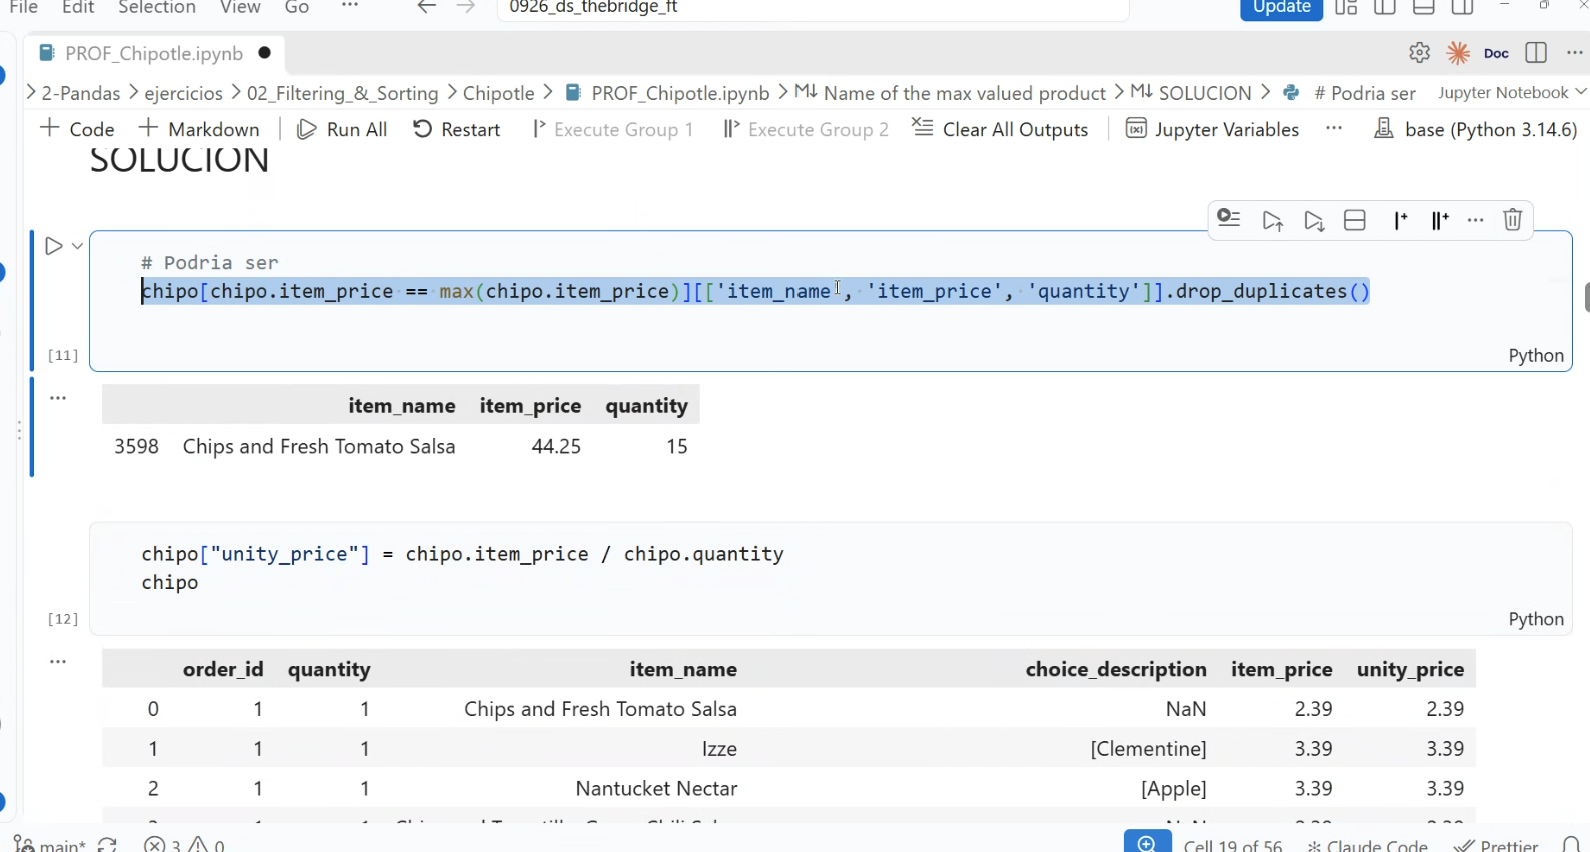

In [ ]:
# max antes mascara booleana y el [] final son las columnas con un fancing indexig lista 
# y quita los duplicados por si hubiera

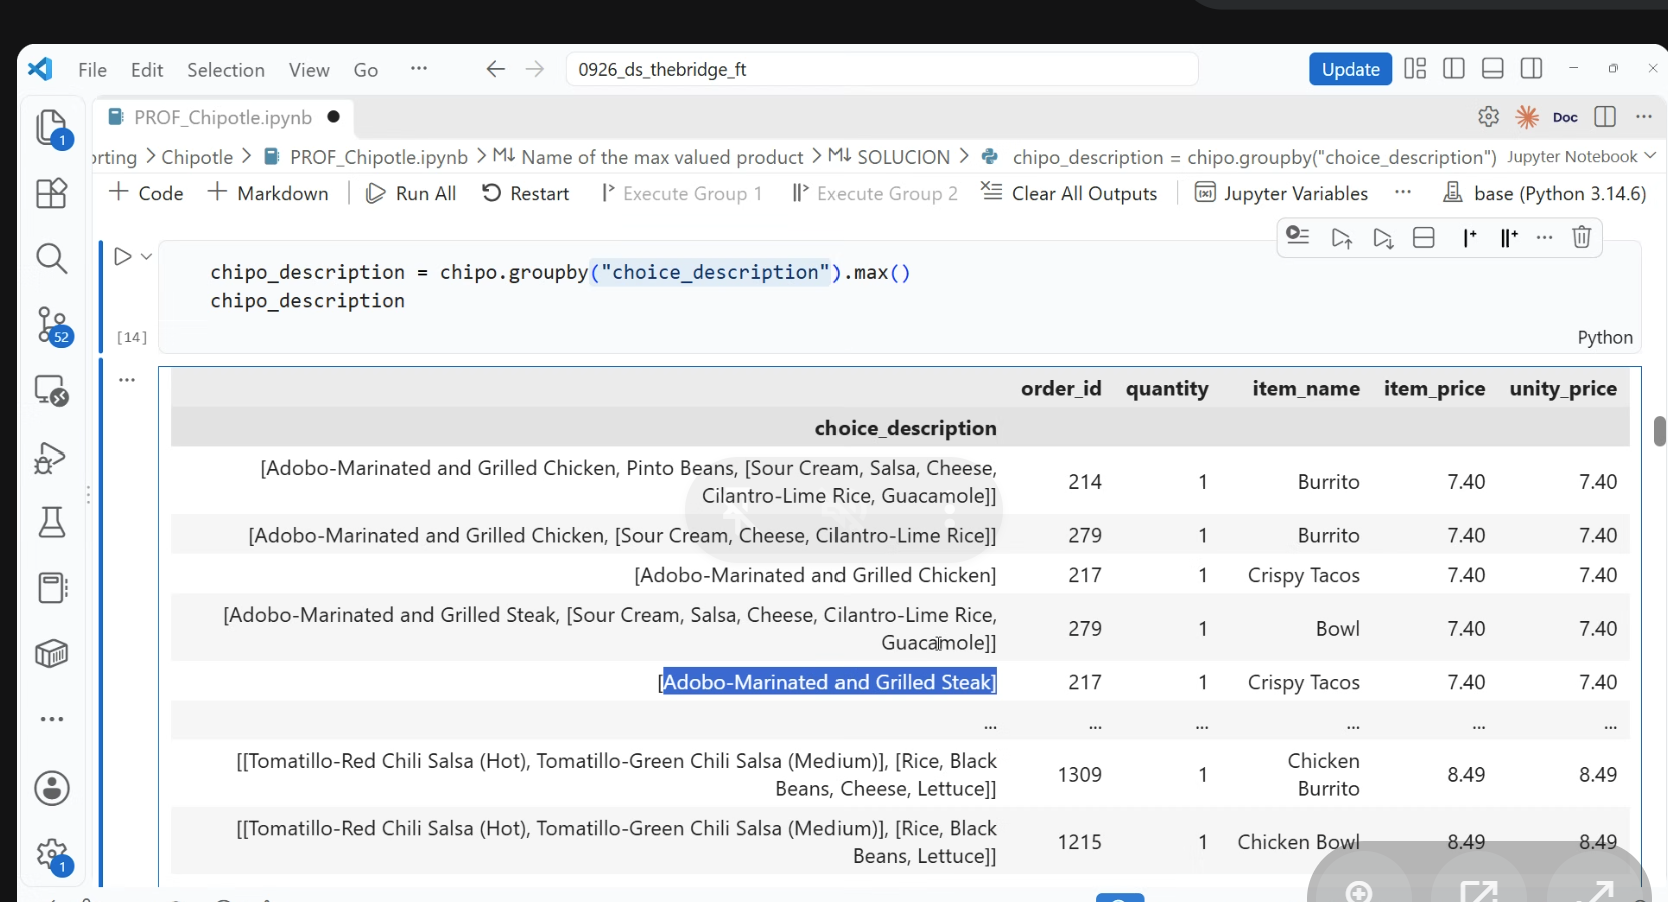

In [ ]:
# agrupa por choice_description por eso se va a la fila y de ahi el max de la columna

In [21]:
chipo["precio_unidad"] = chipo["item_price"] / chipo["quantity"]

# precio por unidad

caros = chipo[chipo["precio_unidad"] > 10]
caros["item_name"].nunique()

# contar los precios de mas de 10. nunique() cuantos productos distintos hay


caros["item_name"].unique() # cuales son
caros

,order_id,quantity,item_name,choice_description,item_price,precio_unidad
5,3,1,Chicken Bowl,"[Fresh Tomato Salsa (Mild), [Rice, Cheese, Sou...",10.98,10.98
7,4,1,Steak Burrito,"[Tomatillo Red Chili Salsa, [Fajita Vegetables...",11.75,11.75
13,7,1,Chicken Bowl,"[Fresh Tomato Salsa, [Fajita Vegetables, Rice,...",11.25,11.25
23,12,1,Chicken Burrito,"[[Tomatillo-Green Chili Salsa (Medium), Tomati...",10.98,10.98
39,19,1,Barbacoa Bowl,"[Roasted Chili Corn Salsa, [Fajita Vegetables,...",11.75,11.75
...,...,...,...,...,...,...
4610,1830,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Sour Cream, Cheese...",11.75,11.75
4611,1830,1,Veggie Burrito,"[Tomatillo Green Chili Salsa, [Rice, Fajita Ve...",11.25,11.25
4617,1833,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Black Beans, Sour ...",11.75,11.75
4618,1833,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Sour Cream, Cheese...",11.75,11.75


### Step 5. What is the price of each item? 
###### print a data frame with only two columns item_name and item_price

In [ ]:
chipo5 = chipo.loc[:, ["item_name", "item_price"]]
chipo5

,item_name,item_price
0,Chips and Fresh Tomato Salsa,$2.39
1,Izze,$3.39
2,Nantucket Nectar,$3.39
3,Chips and Tomatillo-Green Chili Salsa,$2.39
4,Chicken Bowl,$16.98
...,...,...
4617,Steak Burrito,$11.75
4618,Steak Burrito,$11.75
4619,Chicken Salad Bowl,$11.25
4620,Chicken Salad Bowl,$8.75


### Step 6. Sort by the name of the item

In [ ]:
chipo.sort_values("item_name")

,order_id,quantity,item_name,choice_description,item_price
3389,1360,2,6 Pack Soft Drink,[Diet Coke],$12.98
341,148,1,6 Pack Soft Drink,[Diet Coke],$6.49
1849,749,1,6 Pack Soft Drink,[Coke],$6.49
1860,754,1,6 Pack Soft Drink,[Diet Coke],$6.49
2713,1076,1,6 Pack Soft Drink,[Coke],$6.49
...,...,...,...,...,...
2384,948,1,Veggie Soft Tacos,"[Roasted Chili Corn Salsa, [Fajita Vegetables,...",$8.75
781,322,1,Veggie Soft Tacos,"[Fresh Tomato Salsa, [Black Beans, Cheese, Sou...",$8.75
2851,1132,1,Veggie Soft Tacos,"[Roasted Chili Corn Salsa (Medium), [Black Bea...",$8.49
1699,688,1,Veggie Soft Tacos,"[Fresh Tomato Salsa, [Fajita Vegetables, Rice,...",$11.25


### Step 7. What was the quantity of the most expensive item ordered? 2 ways

V1

In [ ]:
chipo.loc[chipo["item_price"].idxmax(), "quantity"]

np.int64(1)

In [ ]:
chipo.sort_values("item_price", ascending=False).head(1)["quantity"]

2624    1
Name: quantity, dtype: int64

V2

### Step 8. How many times was a Veggie Salad Bowl ordered?

In [ ]:
(chipo["item_name"] == "Veggie Salad Bowl").sum()

np.int64(18)

### Step 9. How many times did someone order more than one Canned Soda?

In [ ]:
chipo[(chipo["item_name"] == "Canned Soda") & (chipo["quantity"] > 1)].shape[0]

20